In [6]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.formula.api as smf
from statsmodels.stats.anova import anova_lm
import statsmodels.api as sm
from scipy import stats

Problem 6A

In [7]:
df = pd.read_excel('Framingham(SPSS).xlsx')
anova_df = df[['timestrk', 'diabetes1','cursmoke1']]
anova_df = anova_df.dropna().reset_index(drop=True)

Tests of Between-Subjects Effects (Type III)


,sum_sq,df,F,PR(>F)
Intercept,123269.7579,1.0,2960.9410,0.0000
diabetes1,4385.0448,1.0,105.3288,0.0000
cursmoke1,2.4653,1.0,0.0592,0.8078
diabetes1 * cursmoke1,26.0069,1.0,0.6247,0.4294
Error,184429.5540,4430.0,NaN,NaN



Corrected Model: F(3, 4430) = 40.945, Sig = 0.0000
R Squared = 0.027

Mean timestrk by group:


mean  count
diabetes1 cursmoke1              
No        No         20.35   2174
          Yes        20.00   2139
Yes       No         13.45     79
          Yes        14.09     42

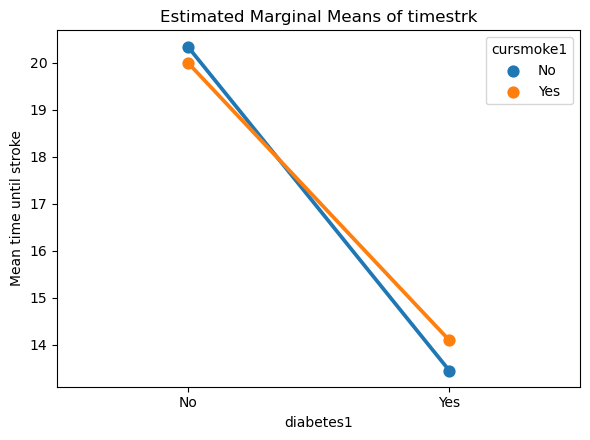

In [8]:
model = smf.ols(
    "timestrk ~ C(diabetes1, Sum) * C(cursmoke1, Sum)", data=anova_df
).fit()
table = anova_lm(model, typ=3)
table.index = ["Intercept", "diabetes1", "cursmoke1",
               "diabetes1 * cursmoke1", "Error"]
print("Tests of Between-Subjects Effects (Type III)")
display(table.round(4))
print(f"\nCorrected Model: F({model.df_model:.0f}, {model.df_resid:.0f}) = "
      f"{model.fvalue:.3f}, Sig = {model.f_pvalue:.4f}")
print(f"R Squared = {model.rsquared:.3f}")
print("\nMean timestrk by group:")
display(anova_df.groupby(["diabetes1", "cursmoke1"])["timestrk"]
        .agg(["mean", "count"]).round(2))
fig, ax = plt.subplots(figsize=(6, 4.5))
sns.pointplot(data=anova_df, x="diabetes1", y="timestrk", hue="cursmoke1",
              errorbar=None, markers="o", ax=ax)
ax.set_title("Estimated Marginal Means of timestrk")
ax.set_ylabel("Mean time until stroke")
fig.tight_layout()
fig.savefig("problem6a_profile_plot.png", dpi=200)


Problem 6B

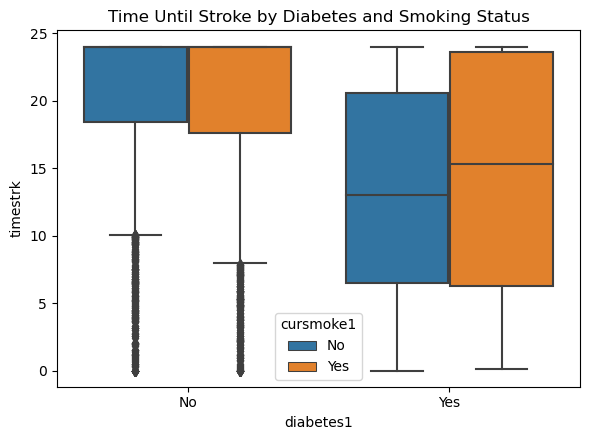

In [9]:
fig, ax = plt.subplots(figsize=(6, 4.5))
sns.boxplot(data=anova_df, x="diabetes1", y="timestrk", hue="cursmoke1", ax=ax)
ax.set_title("Time Until Stroke by Diabetes and Smoking Status")
fig.tight_layout()
fig.savefig("problem6b_boxplot.png", dpi=200)
 
plt.show()